# Optimasi Portofolio Saham LQ45
## Perbandingan Genetic Algorithm, Particle Swarm Optimization, dan Simulated Annealing

## Setup

In [19]:
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Setup library berhasil.")

Setup library berhasil.


## 1. Load Data

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/TA/LQ45_2020_2025.xlsx"

df_raw = pd.read_excel(DATA_PATH, index_col=0, parse_dates=True)

df_raw.index = pd.to_datetime(df_raw.index)
df_raw = df_raw.sort_index()

print("=== DATASET ASLI ===")
print(f"Shape dataset asli      : {df_raw.shape}")
print(f"Jumlah saham awal       : {df_raw.shape[1]}")
print(f"Jumlah hari perdagangan : {df_raw.shape[0]}")
print(f"Total missing value     : {df_raw.isnull().sum().sum()}")

=== DATASET ASLI ===
Shape dataset asli      : (1447, 45)
Jumlah saham awal       : 45
Jumlah hari perdagangan : 1447
Total missing value     : 6392


# summary

In [22]:
print("=== RINGKASAN STATISTIK DATASET AWAL ===")

summary_raw = pd.DataFrame({
    "count": df_raw.count(),
    "mean": df_raw.mean(),
    "median": df_raw.median(),
    "std": df_raw.std(),
    "min": df_raw.min(),
    "max": df_raw.max(),
    "missing_value": df_raw.isnull().sum()
})

display(summary_raw)

=== RINGKASAN STATISTIK DATASET AWAL ===


,count,mean,median,std,min,max,missing_value
AADI.JK,252,7049.199662,6862.818604,737.904450,5396.404297,9643.139648,1195
ADMR.JK,958,1291.979213,1262.880859,359.086548,128.670883,2849.821777,489
ADRO.JK,1447,1065.360278,1139.368042,542.519844,194.011871,2254.575195,0
AKRA.JK,1447,907.759551,1044.838623,374.569499,207.788986,1604.753784,0
AMMN.JK,594,7824.452862,7725.000000,2134.887195,1750.000000,13200.000000,853
AMRT.JK,1447,1907.247958,2034.000732,850.683835,579.390076,3523.521973,0
ANTM.JK,1447,1675.378085,1645.986084,683.370928,285.779785,3670.000000,0
ARTO.JK,1447,5263.732398,2700.000000,4976.021263,274.517670,19000.000000,0
ASII.JK,1447,4427.864360,4413.399414,751.947908,2213.114990,6725.000000,0
BBCA.JK,1447,7448.155890,7744.376953,1535.658547,3829.202148,10500.997070,0


## 2. Data Cleaning

In [23]:
print("=== CEK MISSING VALUE ===")

df_check = df_raw.copy()

missing_value = df_check.isnull().sum()

print(f"Total missing value: {missing_value.sum()}")
print("\nMissing value per saham:")
print(missing_value[missing_value > 0].sort_values(ascending=False))

first_valid = df_check.apply(lambda column: column.first_valid_index())

last_valid = df_check.apply(lambda column: column.last_valid_index())

print("\nTanggal awal data saham yang belum tersedia sejak awal periode:")

late_stocks = first_valid[first_valid > df_check.index.min()].sort_values()

for stock, date in late_stocks.items():
    print(f"  {stock}: data mulai "f"{date.strftime('%d %B %Y')}")


common_start_date = first_valid.max()
common_end_date = last_valid.min()

print("\n=== PERIODE IRISAN SELURUH SAHAM ===")
print("Tanggal awal bersama :", common_start_date.strftime("%A, %d %B %Y"))
print("Tanggal akhir bersama:", common_end_date.strftime("%A, %d %B %Y"))


df_clean = df_check.loc[common_start_date:common_end_date].copy()

df_clean = df_clean.ffill()

df_clean = df_clean.dropna()

print("\n=== HASIL DATA CLEANING ===")

print("Periode tanpa missing value:", df_clean.index.min().strftime("%A, %d %B %Y"), "s/d", df_clean.index.max().strftime("%A, %d %B %Y"))
print(f"Shape akhir             : {df_clean.shape}")
print(f"Jumlah saham            : {df_clean.shape[1]}")
print(f"Jumlah hari perdagangan : {df_clean.shape[0]}")
print(f"Total missing tersisa   : {df_clean.isnull().sum().sum()}")

assert df_clean.shape[1] == df_raw.shape[1], ("Jumlah saham berubah. Seluruh 45 saham harus dipertahankan.")

assert df_clean.isnull().sum().sum() == 0, ("Masih terdapat missing value pada dataset.")

print("\nData cleaning selesai.")

=== CEK MISSING VALUE ===
Total missing value: 6392

Missing value per saham:
AADI.JK    1195
BREN.JK     916
AMMN.JK     853
MBMA.JK     807
NCKL.JK     803
PGEO.JK     773
GOTO.JK     556
ADMR.JK     489
dtype: int64

Tanggal awal data saham yang belum tersedia sejak awal periode:
  ADMR.JK: data mulai 03 January 2022
  GOTO.JK: data mulai 11 April 2022
  PGEO.JK: data mulai 24 February 2023
  NCKL.JK: data mulai 12 April 2023
  MBMA.JK: data mulai 18 April 2023
  AMMN.JK: data mulai 07 July 2023
  BREN.JK: data mulai 09 October 2023
  AADI.JK: data mulai 05 December 2024

=== PERIODE IRISAN SELURUH SAHAM ===
Tanggal awal bersama : Thursday, 05 December 2024
Tanggal akhir bersama: Tuesday, 30 December 2025

=== HASIL DATA CLEANING ===
Periode tanpa missing value: Thursday, 05 December 2024 s/d Tuesday, 30 December 2025
Shape akhir             : (252, 45)
Jumlah saham            : 45
Jumlah hari perdagangan : 252
Total missing tersisa   : 0

Data cleaning selesai.


In [24]:
print("=== RINGKASAN STATISTIK DATASET SETELAH CLEANING ===")

summary_clean = pd.DataFrame({
    "count": df_clean.count(),
    "mean": df_clean.mean(),
    "median": df_clean.median(),
    "std": df_clean.std(),
    "min": df_clean.min(),
    "max": df_clean.max(),
    "missing_value": df_clean.isnull().sum()
})

display(summary_clean)

=== RINGKASAN STATISTIK DATASET SETELAH CLEANING ===


,count,mean,median,std,min,max,missing_value
AADI.JK,252,7049.199662,6862.818604,737.904450,5396.404297,9643.139648,0
ADMR.JK,252,1061.528585,1015.000000,198.765097,671.947937,1600.000000,0
ADRO.JK,252,1739.723147,1706.279053,169.209760,1402.556396,2230.069092,0
AKRA.JK,252,1165.159630,1192.851685,90.850728,832.222107,1345.000000,0
AMMN.JK,252,7414.543651,7237.500000,955.755417,4610.000000,9550.000000,0
AMRT.JK,252,2281.872466,2250.000000,329.524424,1785.000000,3030.031494,0
ANTM.JK,252,2509.579498,2910.000000,772.385622,1314.547974,3670.000000,0
ARTO.JK,252,2017.559524,2005.000000,284.395452,1280.000000,2700.000000,0
ASII.JK,252,5090.100654,4654.994629,811.972930,4125.183105,6725.000000,0
BBCA.JK,252,8531.606042,8469.014648,584.717229,7202.388184,10047.386719,0


## 3. Perhitungan Return dan Matriks Kovarians

In [25]:
returns = df_clean.pct_change(fill_method=None).dropna()

mean_ret = returns.mean().values

cov_matrix = returns.cov().values

n_assets = len(mean_ret)
stock_names = df_clean.columns.tolist()

print("=== PERHITUNGAN RETURN DAN MATRIKS KOVARIANS ===")
print(f"Jumlah saham            : {n_assets}")
print(f"Jumlah hari return      : {len(returns)}")
print(f"Shape matriks kovarians : {cov_matrix.shape}")
print(f"Total missing return    : {returns.isnull().sum().sum()}")

assert n_assets == df_clean.shape[1], ("Jumlah saham pada return tidak sesuai dengan dataset bersih.")

assert cov_matrix.shape == (n_assets, n_assets), ("Ukuran matriks kovarians tidak sesuai dengan jumlah saham.")

assert returns.isnull().sum().sum() == 0, ("Masih terdapat missing value pada data return.")

print("\nPerhitungan return dan matriks kovarians selesai.")

=== PERHITUNGAN RETURN DAN MATRIKS KOVARIANS ===
Jumlah saham            : 45
Jumlah hari return      : 251
Shape matriks kovarians : (45, 45)
Total missing return    : 0

Perhitungan return dan matriks kovarians selesai.


## 4. Fungsi Pendukung

In [26]:
TRADING_DAYS = 252

RISK_FREE_RATE = 0.0475


def repair(w):
    """
    Memastikan bobot portofolio memenuhi constraint dasar:
    1. Bobot tidak negatif (long-only)
    2. Total bobot sama dengan 1
    """
    w = np.clip(w, 0, None)

    total_weight = np.sum(w)

    if total_weight == 0:
        return np.ones(len(w)) / len(w)

    return w / total_weight


def portfolio_variance(w):
    """
    Menghitung varians harian portofolio.
    Fungsi ini menjadi objective function yang diminimalkan.
    """
    return float(w @ cov_matrix @ w)


def portfolio_return(w):
    """
    Menghitung rata-rata return harian portofolio.
    """
    return float(w @ mean_ret)


def annual_return(w):
    """
    Menghitung estimasi return tahunan portofolio.
    """
    return portfolio_return(w) * TRADING_DAYS


def annual_volatility(w):
    """
    Menghitung volatilitas tahunan portofolio.
    """
    return np.sqrt(portfolio_variance(w)) * np.sqrt(TRADING_DAYS)


def sharpe_ratio(w):
    """
    Menghitung Sharpe ratio tahunan.
    """
    ret = annual_return(w)
    vol = annual_volatility(w)

    if vol == 0:
        return 0.0

    return (ret - RISK_FREE_RATE) / vol


equal_weight = np.ones(n_assets) / n_assets
equal_weight = repair(equal_weight)

print("=== VERIFIKASI FUNGSI PENDUKUNG ===")
print(f"Jumlah bobot                  : {equal_weight.sum():.6f}")
print(f"Bobot terkecil                : {equal_weight.min():.6f}")
print(f"Bobot terbesar                : {equal_weight.max():.6f}")
print(f"Varians portofolio harian     : {portfolio_variance(equal_weight):.10f}")
print(f"Return portofolio tahunan     : {annual_return(equal_weight):.4%}")
print(f"Volatilitas portofolio tahunan: {annual_volatility(equal_weight):.4%}")
print(f"Sharpe ratio                  : {sharpe_ratio(equal_weight):.6f}")

# Validasi constraint dasar
assert np.isclose(equal_weight.sum(), 1.0), ("Total bobot portofolio tidak sama dengan 1.")

assert np.all(equal_weight >= 0), ("Masih terdapat bobot negatif.")

print("\nFungsi pendukung siap digunakan.")

=== VERIFIKASI FUNGSI PENDUKUNG ===
Jumlah bobot                  : 1.000000
Bobot terkecil                : 0.022222
Bobot terbesar                : 0.022222
Varians portofolio harian     : 0.0001970023
Return portofolio tahunan     : 23.4553%
Volatilitas portofolio tahunan: 22.2811%
Sharpe ratio                  : 0.839514

Fungsi pendukung siap digunakan.


## 5. Parameter Algoritma

In [27]:
MAX_FES = 10_000
N_RUNS = 100

GA_POP = 50
GA_PC = 0.80
GA_PM = 0.10
GA_SIGMA = 0.05

GA_GEN = (MAX_FES - GA_POP) // GA_POP


PSO_PARTICLES = 30
PSO_W_MAX = 0.90
PSO_W_MIN = 0.40
PSO_C1 = 1.50
PSO_C2 = 1.50
PSO_V_MAX = 0.20

PSO_ITER = (MAX_FES - PSO_PARTICLES) // PSO_PARTICLES


SA_T0 = 1.0
SA_T_MIN = 1e-6
SA_DELTA = 0.05

SA_MAX_ITER = MAX_FES - 1
SA_COOLING_RATE = (SA_T_MIN / SA_T0) ** (1 / SA_MAX_ITER)


ga_total_fes = GA_POP + (GA_GEN * GA_POP)
pso_total_fes = PSO_PARTICLES + (PSO_ITER * PSO_PARTICLES)
sa_total_fes = 1 + SA_MAX_ITER

print("\n=== CATATAN ANGGARAN EVALUASI ===")
print(f"GA : {ga_total_fes:,} evaluations")
print(f"PSO: {pso_total_fes:,} evaluations")
print(f"SA : {sa_total_fes:,} evaluations")

print(
    "Note: The algorithms use nearly equal, "
    "but not identical, function evaluation budgets."
)

print("=" * 65)
print("PARAMETER ALGORITMA")
print("=" * 65)

print("\n=== BUDGET EKSPERIMEN ===")
print(f"Maksimum evaluasi fungsi objektif : {MAX_FES:,}")
print(f"Jumlah pengujian berulang         : {N_RUNS}")

print("\n=== GENETIC ALGORITHM ===")
print(f"Populasi                          : {GA_POP}")
print(f"Generasi                          : {GA_GEN}")
print(f"Probabilitas crossover            : {GA_PC}")
print(f"Probabilitas mutasi               : {GA_PM}")
print(f"Sigma mutasi                      : {GA_SIGMA}")
print(f"Total evaluasi                    : {ga_total_fes:,}")

print("\n=== PARTICLE SWARM OPTIMIZATION ===")
print(f"Jumlah partikel                   : {PSO_PARTICLES}")
print(f"Iterasi                           : {PSO_ITER}")
print(f"Inertia weight                    : {PSO_W_MAX} -> {PSO_W_MIN}")
print(f"Koefisien kognitif                : {PSO_C1}")
print(f"Koefisien sosial                  : {PSO_C2}")
print(f"Velocity maksimum                 : {PSO_V_MAX}")
print(f"Total evaluasi                    : {pso_total_fes:,}")

print("\n=== SIMULATED ANNEALING ===")
print(f"Temperatur awal                   : {SA_T0}")
print(f"Temperatur minimum                : {SA_T_MIN}")
print(f"Cooling rate                      : {SA_COOLING_RATE:.6f}")
print(f"Delta transfer bobot              : {SA_DELTA}")
print(f"Iterasi maksimum                  : {SA_MAX_ITER}")
print(f"Total evaluasi                    : {sa_total_fes:,}")


=== CATATAN ANGGARAN EVALUASI ===
GA : 10,000 evaluations
PSO: 9,990 evaluations
SA : 10,000 evaluations
Note: The algorithms use nearly equal, but not identical, function evaluation budgets.
PARAMETER ALGORITMA

=== BUDGET EKSPERIMEN ===
Maksimum evaluasi fungsi objektif : 10,000
Jumlah pengujian berulang         : 100

=== GENETIC ALGORITHM ===
Populasi                          : 50
Generasi                          : 199
Probabilitas crossover            : 0.8
Probabilitas mutasi               : 0.1
Sigma mutasi                      : 0.05
Total evaluasi                    : 10,000

=== PARTICLE SWARM OPTIMIZATION ===
Jumlah partikel                   : 30
Iterasi                           : 332
Inertia weight                    : 0.9 -> 0.4
Koefisien kognitif                : 1.5
Koefisien sosial                  : 1.5
Velocity maksimum                 : 0.2
Total evaluasi                    : 9,990

=== SIMULATED ANNEALING ===
Temperatur awal                   : 1.0
Temperatur mi

## 6. Implementasi Genetic Algorithm (GA)
Binary tournament selection, arithmetic crossover, Gaussian mutation, elitism

In [29]:
def run_ga(seed=42):
    """
    Menjalankan Genetic Algorithm untuk mencari bobot portofolio
    dengan varians minimum.

    Parameters
    ----------
    seed : int
        Seed untuk memastikan hasil dapat direproduksi.

    Returns
    -------
    best : numpy.ndarray
        Bobot portofolio terbaik.
    best_fit : float
        Nilai varians minimum terbaik.
    history : list
        Riwayat nilai varians terbaik pada setiap generasi.
    """

    rng = np.random.default_rng(seed)

    pop = [repair(rng.random(n_assets))for _ in range(GA_POP)]

    fitness = np.array([portfolio_variance(individual)for individual in pop])

    best_idx = np.argmin(fitness)
    best = pop[best_idx].copy()
    best_fit = fitness[best_idx]

    history = [best_fit]

    for gen in range(GA_GEN):

        new_pop = [best.copy()]

        while len(new_pop) < GA_POP:

            i1, i2 = rng.integers(0,GA_POP,size=2)

            p1 = (pop[i1]if fitness[i1] < fitness[i2]else pop[i2])

            i1, i2 = rng.integers(0,GA_POP,size=2)

            p2 = ( pop[i1]if fitness[i1] < fitness[i2]else pop[i2])

            if rng.random() < GA_PC:
                alpha = rng.random()

                child = (alpha * p1 + (1 - alpha) * p2)

            else:
                child = p1.copy()

            if rng.random() < GA_PM:child += rng.normal(loc=0,scale=GA_SIGMA,size=n_assets)

            child = repair(child)

            new_pop.append(child)

        pop = new_pop

        fitness = np.array([portfolio_variance(individual)for individual in pop])

        gen_best_idx = np.argmin(fitness)

        if fitness[gen_best_idx] < best_fit:
            best = pop[gen_best_idx].copy()
            best_fit = fitness[gen_best_idx]

        history.append(best_fit)

    return best, best_fit, history


print("Implementasi Genetic Algorithm siap digunakan.")

Implementasi Genetic Algorithm siap digunakan.


## 7. Implementasi Particle Swarm Optimization (PSO)
Linear decreasing inertia weight, velocity clamping, repair constraint handling

In [30]:
def run_pso(seed=42):
    """
    Menjalankan Particle Swarm Optimization untuk mencari
    bobot portofolio dengan varians minimum.

    Parameters
    ----------
    seed : int
        Seed agar hasil dapat direproduksi.

    Returns
    -------
    gbest : numpy.ndarray
        Bobot portofolio terbaik.
    gbest_fit : float
        Nilai varians minimum terbaik.
    history : list
        Riwayat nilai varians terbaik pada setiap iterasi.
    """

    rng = np.random.default_rng(seed)

    pos = np.array([
        repair(rng.random(n_assets))
        for _ in range(PSO_PARTICLES)
    ])

    vel = np.zeros((PSO_PARTICLES, n_assets))

    pbest = pos.copy()

    pbest_fit = np.array([portfolio_variance(particle)for particle in pos])

    gbest_idx = np.argmin(pbest_fit)

    gbest = pbest[gbest_idx].copy()

    gbest_fit = pbest_fit[gbest_idx]

    history = [gbest_fit]

    for t in range(PSO_ITER):

        if PSO_ITER > 1:
            inertia_weight = (PSO_W_MAX - (PSO_W_MAX - PSO_W_MIN) * t / (PSO_ITER - 1))
        else:
            inertia_weight = PSO_W_MIN

        for i in range(PSO_PARTICLES):

            r1 = rng.random(n_assets)
            r2 = rng.random(n_assets)

            vel[i] = (inertia_weight * vel[i]+ PSO_C1 * r1 * (pbest[i] - pos[i])+ PSO_C2 * r2 * (gbest - pos[i]))

            vel[i] = np.clip(vel[i], -PSO_V_MAX, PSO_V_MAX)

            pos[i] = pos[i] + vel[i]

            pos[i] = repair(pos[i])

            fit = portfolio_variance(pos[i])

            if fit < pbest_fit[i]:
                pbest[i] = pos[i].copy()
                pbest_fit[i] = fit

        best_particle = np.argmin(pbest_fit)

        if pbest_fit[best_particle] < gbest_fit:
            gbest = pbest[best_particle].copy()

            gbest_fit = pbest_fit[best_particle]

        history.append(gbest_fit)

    return gbest, gbest_fit, history

print("Implementasi Particle Swarm Optimization siap digunakan.")

Implementasi Particle Swarm Optimization siap digunakan.


## 8. Implementasi Simulated Annealing (SA)
Weight transfer neighbor (Pers. 2.14), Metropolis acceptance (Pers. 2.12), geometric cooling (Pers. 2.13)

In [31]:
def run_sa(seed=42):
    """
    Menjalankan Simulated Annealing untuk mencari bobot portofolio
    dengan varians minimum.

    Parameters
    ----------
    seed : int
        Seed agar hasil dapat direproduksi.

    Returns
    -------
    best : numpy.ndarray
        Bobot portofolio terbaik.
    best_fit : float
        Nilai varians minimum terbaik.
    history : list
        Riwayat nilai varians terbaik pada setiap iterasi.
    """

    rng = np.random.default_rng(seed)

    current = repair(rng.random(n_assets))

    current_fit = portfolio_variance(current)

    best = current.copy()
    best_fit = current_fit

    history = [best_fit]

    temperature = SA_T0

    cooling_rate = (SA_T_MIN / SA_T0) ** (1 / SA_MAX_ITER)

    for _ in range(SA_MAX_ITER):

        neighbor = current.copy()

        i, j = rng.choice(n_assets, size=2, replace=False)

        max_delta = min(SA_DELTA, neighbor[i])

        if max_delta > 0:
            delta = rng.uniform(0, max_delta)

            neighbor[i] -= delta
            neighbor[j] += delta

        neighbor = repair(neighbor)

        neighbor_fit = portfolio_variance(neighbor)

        delta_f = (neighbor_fit - current_fit)

        if (delta_f <= 0 or rng.random() < np.exp(-delta_f / max(temperature, 1e-12))):
            current = neighbor
            current_fit = neighbor_fit

        if current_fit < best_fit:
            best = current.copy()
            best_fit = current_fit

        temperature *= cooling_rate

        history.append(best_fit)

    return best, best_fit, history

print("Implementasi Simulated Annealing siap digunakan.")

Implementasi Simulated Annealing siap digunakan.


## 9. Eksperimen

In [32]:
def run_experiment(algo_func, name, runs=N_RUNS):
    """
    Menjalankan algoritma secara berulang dan mencatat hasilnya.
    """

    results = []
    histories = []

    print("\n" + "=" * 55)
    print(f"  {name} - {runs} runs")
    print("=" * 55)

    for i in range(runs):
        start = time.time()

        weights, best_fit, history = algo_func(seed=SEED + i)

        elapsed = time.time() - start

        results.append({"run": i + 1, "variance": best_fit, "annual_return": annual_return(weights), "annual_volatility": annual_volatility(weights), "sharpe_ratio": sharpe_ratio(weights), "execution_time": elapsed, "weights": weights})

        histories.append(history)

        if (i + 1) % 10 == 0 or i == 0:
            print(f"Run {i + 1:3d}/{runs} | " f"Variance: {best_fit:.10f} | " f"Time: {elapsed:.4f} detik")

    print(f"\n{name} selesai dijalankan.")

    return results, histories

In [33]:
ga_results, ga_histories = run_experiment(run_ga, "Genetic Algorithm (GA)")

pso_results, pso_histories = run_experiment(run_pso, "Particle Swarm Optimization (PSO)")

sa_results, sa_histories = run_experiment(run_sa, "Simulated Annealing (SA)")


  Genetic Algorithm (GA) - 100 runs
Run   1/100 | Variance: 0.0001363114 | Time: 0.5436 detik
Run  10/100 | Variance: 0.0001205087 | Time: 0.4758 detik
Run  20/100 | Variance: 0.0001213812 | Time: 0.7558 detik
Run  30/100 | Variance: 0.0001365307 | Time: 0.4799 detik
Run  40/100 | Variance: 0.0001332741 | Time: 0.4924 detik
Run  50/100 | Variance: 0.0001260485 | Time: 0.4783 detik
Run  60/100 | Variance: 0.0001261443 | Time: 0.4787 detik
Run  70/100 | Variance: 0.0001241465 | Time: 0.7484 detik
Run  80/100 | Variance: 0.0001297695 | Time: 0.4857 detik
Run  90/100 | Variance: 0.0001229562 | Time: 0.4867 detik
Run 100/100 | Variance: 0.0001236218 | Time: 0.7936 detik

Genetic Algorithm (GA) selesai dijalankan.

  Particle Swarm Optimization (PSO) - 100 runs
Run   1/100 | Variance: 0.0000885490 | Time: 0.7128 detik
Run  10/100 | Variance: 0.0000874281 | Time: 0.4156 detik
Run  20/100 | Variance: 0.0000862676 | Time: 0.4130 detik
Run  30/100 | Variance: 0.0000882069 | Time: 0.7001 detik
R

## 10. Hasil dan Analisis

### 10.1 Summary Statistics

In [34]:
def make_summary(results):
    metrics = {
        "Variance": [r["variance"] for r in results],
        "Annual Return": [r["annual_return"] for r in results],
        "Annual Volatility": [r["annual_volatility"] for r in results],
        "Sharpe Ratio": [r["sharpe_ratio"] for r in results],
        "Time/run": [r["execution_time"] for r in results],
    }

    summary = {}

    for metric_name, values in metrics.items():
        values = np.array(values, dtype=float)

        summary[f"{metric_name} (mean)"] = np.mean(values)
        summary[f"{metric_name} (std)"] = np.std(values)
        summary[f"{metric_name} (min)"] = np.min(values)
        summary[f"{metric_name} (max)"] = np.max(values)

    return summary


summary_df = pd.DataFrame({
    "GA": make_summary(ga_results),
    "PSO": make_summary(pso_results),
    "SA": make_summary(sa_results),
})

print("\n=== SUMMARY STATISTICS LENGKAP (100 RUNS) ===")
display(summary_df)


=== SUMMARY STATISTICS LENGKAP (100 RUNS) ===


,GA,PSO,SA
Variance (mean),0.000127,0.000092,0.000108
Variance (std),0.000006,0.000006,0.000006
Variance (min),0.000111,0.000086,0.000095
Variance (max),0.000139,0.000113,0.000133
Annual Return (mean),0.172364,0.065404,0.135025
Annual Return (std),0.038635,0.039259,0.045437
Annual Return (min),0.032149,-0.053087,0.029727
Annual Return (max),0.255224,0.179282,0.245095
Annual Volatility (mean),0.178913,0.151932,0.165183
Annual Volatility (std),0.004088,0.004827,0.004725


### 10.2 Ranking Minimum Variance

In [35]:
print("\n=== RANKING (MINIMUM VARIANCE - MEAN) ===")
ranking = summary_df.loc['Variance (mean)'].sort_values()
for i, (algo, val) in enumerate(ranking.items(), 1):
    print(f"  {i}. {algo}: {val:.6f}")

print("\n=== RANKING (MINIMUM VARIANCE - BEST SINGLE RUN) ===")
ranking_min = summary_df.loc['Variance (min)'].sort_values()
for i, (algo, val) in enumerate(ranking_min.items(), 1):
    print(f"  {i}. {algo}: {val:.6f}")


=== RANKING (MINIMUM VARIANCE - MEAN) ===
  1. PSO: 0.000092
  2. SA: 0.000108
  3. GA: 0.000127

=== RANKING (MINIMUM VARIANCE - BEST SINGLE RUN) ===
  1. PSO: 0.000086
  2. SA: 0.000095
  3. GA: 0.000111


## 11. Visualisasi

### 11.1 Kurva Konvergensi

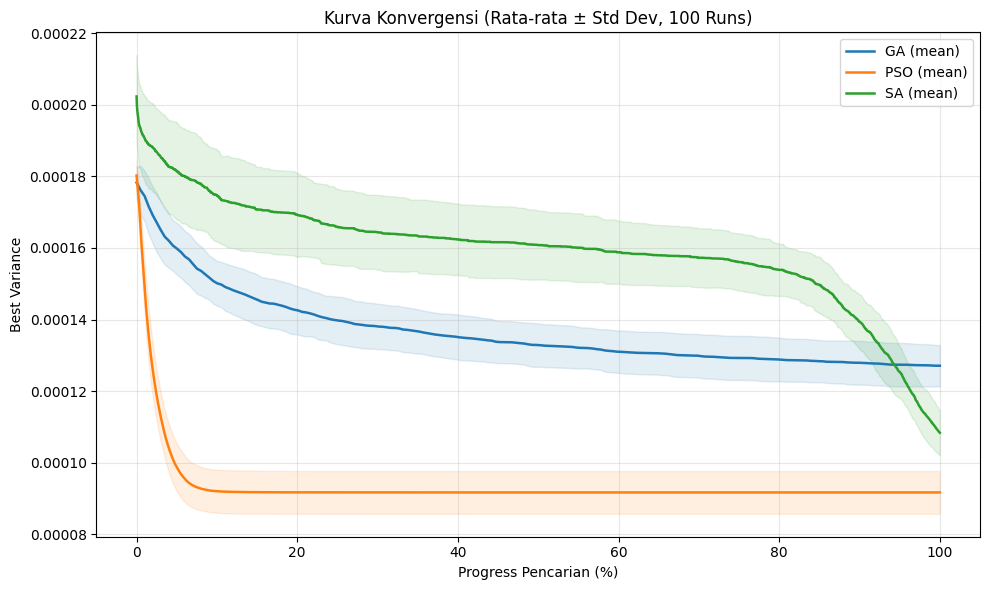

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))

for histories, name, color in [(ga_histories, "GA", "tab:blue"), (pso_histories, "PSO", "tab:orange"), (sa_histories, "SA", "tab:green")]:
    max_len = max(len(h) for h in histories)

    padded = np.array([h + [h[-1]] * (max_len - len(h))for h in histories])

    mean_curve = padded.mean(axis=0)
    std_curve = padded.std(axis=0)

    x = np.linspace(0, 100, max_len)

    ax.plot(x, mean_curve, label=f"{name} (mean)", color=color, linewidth=1.8)

    ax.fill_between(x, mean_curve - std_curve, mean_curve + std_curve, color=color, alpha=0.12)

ax.set_xlabel("Progress Pencarian (%)")
ax.set_ylabel("Best Variance")
ax.set_title("Kurva Konvergensi (Rata-rata ± Std Dev, 100 Runs)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 11.2 Distribusi Metrik

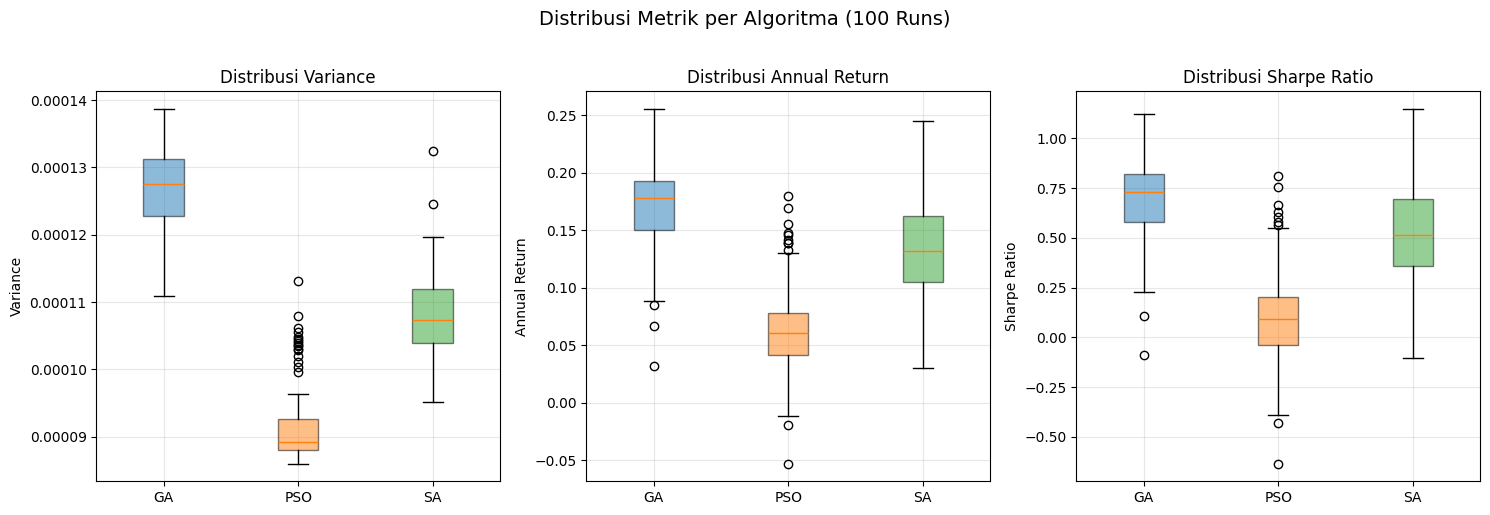

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

data_labels = ["GA", "PSO", "SA"]

all_results = [ga_results, pso_results, sa_results]

colors = ["tab:blue", "tab:orange", "tab:green"]

data_var = [
    [
        result["variance"]
        for result in results
    ]
    for results in all_results
]

boxplot_variance = axes[0].boxplot(data_var, tick_labels=data_labels, patch_artist=True)

for patch, color in zip(boxplot_variance["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

axes[0].set_title("Distribusi Variance")

axes[0].set_ylabel("Variance")

axes[0].grid(True, alpha=0.3)

data_return = [
    [
        result["annual_return"]
        for result in results
    ]
    for results in all_results
]

boxplot_return = axes[1].boxplot(data_return, tick_labels=data_labels, patch_artist=True)

for patch, color in zip(boxplot_return["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

axes[1].set_title("Distribusi Annual Return")

axes[1].set_ylabel("Annual Return")

axes[1].grid(True, alpha=0.3)

data_sharpe = [
    [
        result["sharpe_ratio"]
        for result in results
    ]
    for results in all_results
]

boxplot_sharpe = axes[2].boxplot(data_sharpe, tick_labels=data_labels, patch_artist=True)

for patch, color in zip(boxplot_sharpe["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

axes[2].set_title("Distribusi Sharpe Ratio")

axes[2].set_ylabel("Sharpe Ratio")

axes[2].grid(True, alpha=0.3)

plt.suptitle("Distribusi Metrik per Algoritma (100 Runs)", fontsize=14, y=1.02)

plt.tight_layout()
plt.show()

### 11.3 Perbandingan Rata-rata Metrik

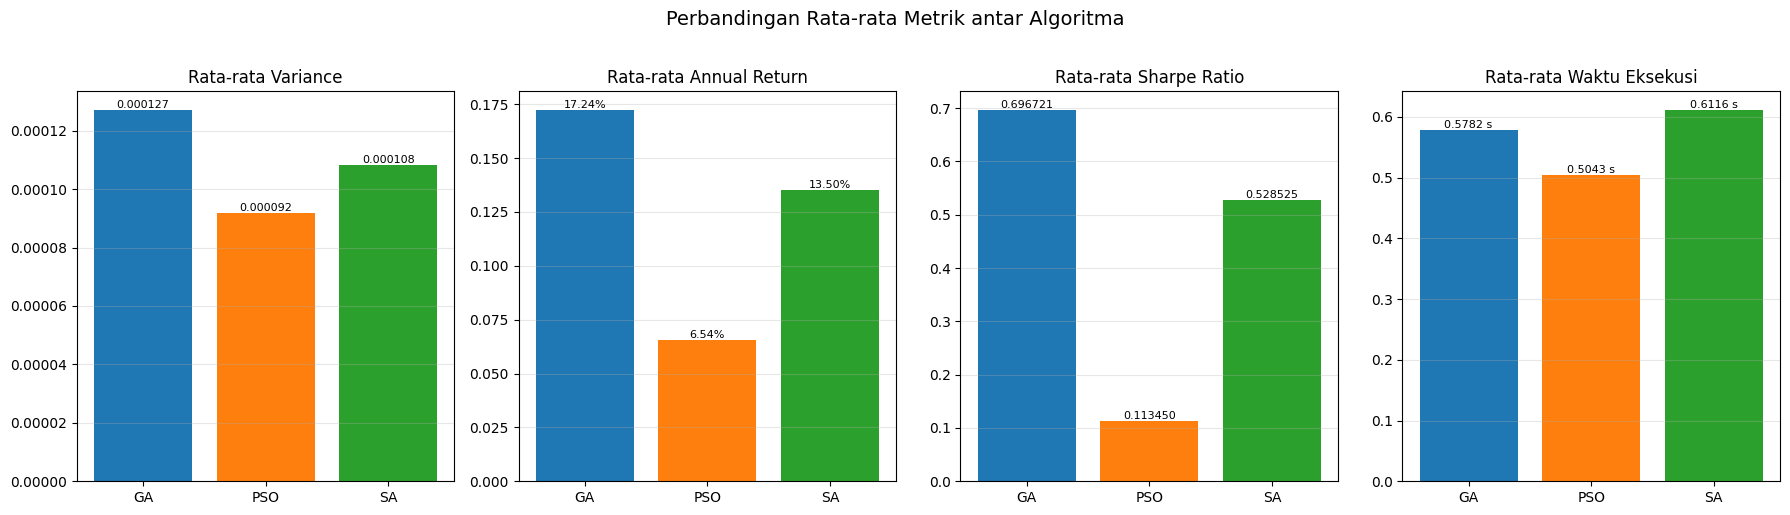

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

algos = ["GA", "PSO", "SA"]

colors = ["tab:blue", "tab:orange", "tab:green"]

metrics = [
    ("Variance (mean)", "Rata-rata Variance", "decimal"), ("Annual Return (mean)", "Rata-rata Annual Return", "percent"),
    ("Sharpe Ratio (mean)", "Rata-rata Sharpe Ratio", "decimal"), ("Time/run (mean)", "Rata-rata Waktu Eksekusi", "seconds")
]

for ax, (metric, title, value_type) in zip(axes, metrics):
    values = [
        summary_df.loc[
            metric,
            algo
        ]
        for algo in algos
    ]

    bars = ax.bar(algos, values, color=colors)

    ax.set_title(title)
    ax.grid(True, alpha=0.3, axis="y")

    for bar, value in zip(bars, values):
        if value_type == "percent":
            label = f"{value:.2%}"

        elif value_type == "seconds":
            label = f"{value:.4f} s"

        else:
            label = f"{value:.6f}"

        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height(), label, ha="center", va="bottom", fontsize=8
        )

plt.suptitle("Perbandingan Rata-rata Metrik antar Algoritma", fontsize=14, y=1.02)

plt.tight_layout()
plt.show()

### 11.4 Portofolio Terbaik per Algoritma

In [39]:
print("\n=== PORTOFOLIO TERBAIK PER ALGORITMA ===\n")

best_weights = {}

for results, name in [(ga_results, "GA"), (pso_results, "PSO"),(sa_results, "SA")]:
    best = min(results, key=lambda result: result["variance"])

    weights = best["weights"]
    best_weights[name] = weights

    print(f"--- {name} ---")
    print(f"  Variance harian       : {best['variance']:.8f}")
    print(f"  Annual return         : {best['annual_return']:.4%}")
    print(f"  Annual volatility     : {best['annual_volatility']:.4%}")
    print(f"  Sharpe ratio          : {best['sharpe_ratio']:.4f}")
    print(f"  Waktu eksekusi        : {best['execution_time']:.4f} detik")

    weights_series = pd.Series(weights, index=stock_names)

    top_weights = weights_series[weights_series > 0.01].sort_values(ascending=False)

    print(f"  Saham dengan bobot >1%: {len(top_weights)}")

    for stock, weight in top_weights.items():
        print(f"    {stock}: " f"{weight * 100:.2f}%")

    print()


=== PORTOFOLIO TERBAIK PER ALGORITMA ===

--- GA ---
  Variance harian       : 0.00011096
  Annual return         : 8.5200%
  Annual volatility     : 16.7220%
  Sharpe ratio          : 0.2255
  Waktu eksekusi        : 0.8215 detik
  Saham dengan bobot >1%: 20
    ITMG.JK: 17.75%
    ICBP.JK: 11.82%
    HEAL.JK: 7.68%
    INDF.JK: 6.31%
    EXCL.JK: 6.09%
    TLKM.JK: 6.03%
    KLBF.JK: 4.86%
    BBCA.JK: 4.58%
    MEDC.JK: 4.33%
    BMRI.JK: 3.84%
    EMTK.JK: 3.39%
    ASII.JK: 3.21%
    CPIN.JK: 3.07%
    GOTO.JK: 2.87%
    PGEO.JK: 2.36%
    CTRA.JK: 2.13%
    JSMR.JK: 1.52%
    PGAS.JK: 1.30%
    UNVR.JK: 1.29%
    BRIS.JK: 1.13%

--- PSO ---
  Variance harian       : 0.00008600
  Annual return         : 6.8745%
  Annual volatility     : 14.7217%
  Sharpe ratio          : 0.1443
  Waktu eksekusi        : 0.4189 detik
  Saham dengan bobot >1%: 12
    ITMG.JK: 32.16%
    ICBP.JK: 15.44%
    EXCL.JK: 9.56%
    INDF.JK: 8.53%
    PGAS.JK: 8.02%
    ASII.JK: 7.62%
    HEAL.JK: 6.30%
  

In [40]:
def validate_weights(weights, tolerance=1e-8):
    return (
        np.all(weights >= -tolerance)
        and np.isclose(np.sum(weights), 1.0, atol=tolerance)
    )

print("\n=== VALIDASI CONSTRAINT BOBOT PORTOFOLIO ===")

print("GA valid :", validate_weights(best_weights["GA"]))
print("PSO valid:", validate_weights(best_weights["PSO"]))
print("SA valid :", validate_weights(best_weights["SA"]))


=== VALIDASI CONSTRAINT BOBOT PORTOFOLIO ===
GA valid : True
PSO valid: True
SA valid : True


### 11.5 Distribusi Bobot Portofolio Terbaik

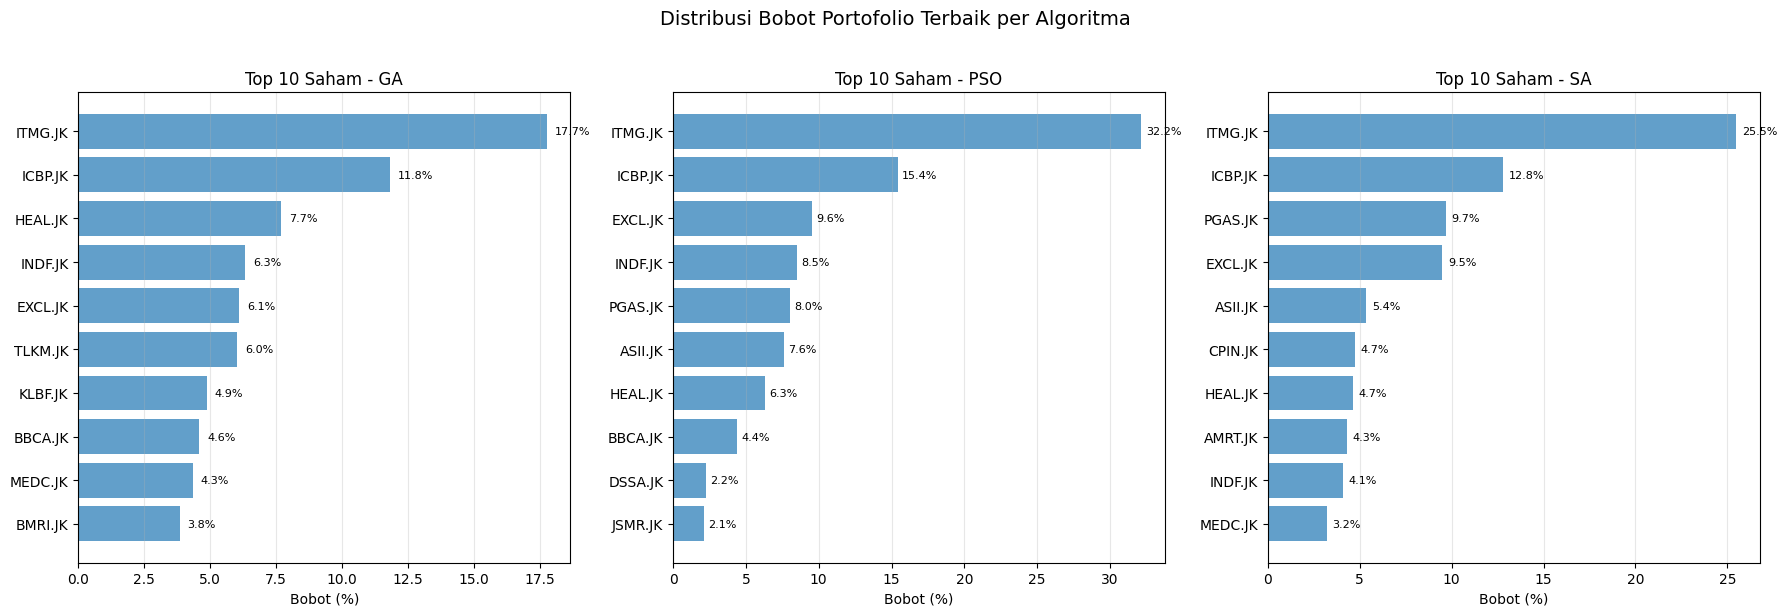

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, weights) in zip(axes, best_weights.items()):
    weights_series = pd.Series(weights, index=stock_names)

    top10 = weights_series.sort_values(ascending=False).head(10)

    bars = ax.barh(range(len(top10)), top10.values * 100, color="tab:blue", alpha=0.7)

    ax.set_yticks(range(len(top10)))
    ax.set_yticklabels(top10.index)
    ax.set_xlabel("Bobot (%)")
    ax.set_title(f"Top 10 Saham - {name}")
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3, axis="x")

    for bar, value in zip(bars, top10.values * 100):
        ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%", va="center", fontsize=8)

plt.suptitle("Distribusi Bobot Portofolio Terbaik per Algoritma", fontsize=14, y=1.02)

plt.tight_layout()
plt.show()

### 11.6 Distribusi Waktu Eksekusi

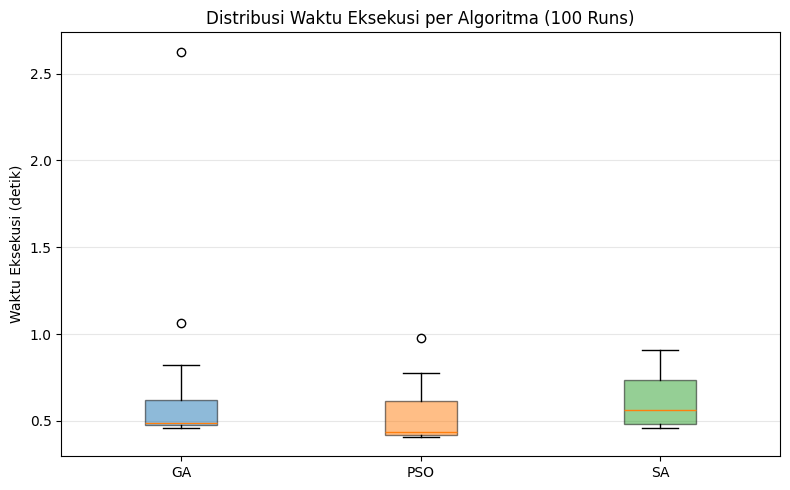

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))

time_data = [
    [
        result["execution_time"]
        for result in results
    ]
    for results in [
        ga_results, pso_results, sa_results
    ]
]

boxplot_time = ax.boxplot(time_data, tick_labels=["GA", "PSO", "SA"], patch_artist=True)

for patch, color in zip(boxplot_time["boxes"], ["tab:blue", "tab:orange", "tab:green"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax.set_title("Distribusi Waktu Eksekusi per Algoritma (100 Runs)")

ax.set_ylabel("Waktu Eksekusi (detik)")

ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

## 12. Tabel Ringkasan Akhir

In [43]:
print("\n" + "=" * 70)
print("TABEL RINGKASAN AKHIR")
print("=" * 70)

final_data = {}

for algo in ["GA", "PSO", "SA"]:
    final_data[algo] = {
        "Variance (rata-rata)": (
            f"{summary_df.loc['Variance (mean)', algo]:.6f}"
        ),

        "Variance (std)": (
            f"{summary_df.loc['Variance (std)', algo]:.6f}"
        ),

        "Variance (minimum)": (
            f"{summary_df.loc['Variance (min)', algo]:.6f}"
        ),

        "Variance (maksimum)": (
            f"{summary_df.loc['Variance (max)', algo]:.6f}"
        ),

        "Annual return (rata-rata)": (
            f"{summary_df.loc['Annual Return (mean)', algo]:.2%}"
        ),

        "Annual return (std)": (
            f"{summary_df.loc['Annual Return (std)', algo]:.2%}"
        ),

        "Annual volatility (rata-rata)": (
            f"{summary_df.loc['Annual Volatility (mean)', algo]:.2%}"
        ),

        "Annual volatility (std)": (
            f"{summary_df.loc['Annual Volatility (std)', algo]:.2%}"
        ),

        "Sharpe ratio (rata-rata)": (
            f"{summary_df.loc['Sharpe Ratio (mean)', algo]:.4f}"
        ),

        "Sharpe ratio (std)": (
            f"{summary_df.loc['Sharpe Ratio (std)', algo]:.4f}"
        ),

        "Waktu rata-rata (detik)": (
            f"{summary_df.loc['Time/run (mean)', algo]:.4f}"
        ),

        "Waktu std (detik)": (
            f"{summary_df.loc['Time/run (std)', algo]:.4f}"
        )
    }

final_table = pd.DataFrame(final_data)

display(final_table)


TABEL RINGKASAN AKHIR


,GA,PSO,SA
Variance (rata-rata),0.000127,0.000092,0.000108
Variance (std),0.000006,0.000006,0.000006
Variance (minimum),0.000111,0.000086,0.000095
Variance (maksimum),0.000139,0.000113,0.000133
Annual return (rata-rata),17.24%,6.54%,13.50%
Annual return (std),3.86%,3.93%,4.54%
Annual volatility (rata-rata),17.89%,15.19%,16.52%
Annual volatility (std),0.41%,0.48%,0.47%
Sharpe ratio (rata-rata),0.6967,0.1135,0.5285
Sharpe ratio (std),0.2140,0.2477,0.2717


# Output Tabel

In [44]:
def format_decimal(value, digits=6):
    return f"{value:.{digits}f}".replace(".", ",")


def format_percent(value, digits=2):
    return f"{value:.{digits}%}".replace(".", ",")


def format_seconds(value, digits=4):
    return f"{value:.{digits}f} detik".replace(".", ",")


def make_thesis_summary_table(results):
    """
    Membuat tabel ringkasan dengan format:
    Metrik, Nilai Rata-Rata, Standar Deviasi, Nilai Minimum, Nilai Maksimum.
    """

    df = pd.DataFrame(results)

    table_rows = []

    metric_config = [
        ("Varians portofolio", "variance", "decimal6"),
        ("Annual return", "annual_return", "percent2"),
        ("Annual volatility", "annual_volatility", "percent2"),
        ("Sharpe ratio", "sharpe_ratio", "decimal4"),
        ("Waktu eksekusi", "execution_time", "seconds4"),
    ]

    for metric_label, column_name, value_type in metric_config:
        values = df[column_name].astype(float)

        mean_value = values.mean()
        std_value = values.std(ddof=0)
        min_value = values.min()
        max_value = values.max()

        if value_type == "decimal6":
            mean_text = format_decimal(mean_value, 6)
            std_text = format_decimal(std_value, 6)
            min_text = format_decimal(min_value, 6)
            max_text = format_decimal(max_value, 6)

        elif value_type == "percent2":
            mean_text = format_percent(mean_value, 2)
            std_text = format_percent(std_value, 2)
            min_text = format_percent(min_value, 2)
            max_text = format_percent(max_value, 2)

        elif value_type == "decimal4":
            mean_text = format_decimal(mean_value, 4)
            std_text = format_decimal(std_value, 4)
            min_text = format_decimal(min_value, 4)
            max_text = format_decimal(max_value, 4)

        elif value_type == "seconds4":
            mean_text = format_seconds(mean_value, 4)
            std_text = format_seconds(std_value, 4)
            min_text = format_seconds(min_value, 4)
            max_text = format_seconds(max_value, 4)

        table_rows.append({
            "Metrik": metric_label,
            "Nilai Rata-Rata": mean_text,
            "Standar Deviasi": std_text,
            "Nilai Minimum": min_text,
            "Nilai Maksimum": max_text,
        })

    return pd.DataFrame(table_rows)

In [45]:
tabel_413_ga = make_thesis_summary_table(ga_results)
tabel_416_pso = make_thesis_summary_table(pso_results)
tabel_419_sa = make_thesis_summary_table(sa_results)

print("Tabel 4.13 Ringkasan Hasil Pengujian GA")
display(tabel_413_ga)

print("Tabel 4.16 Ringkasan Hasil Pengujian PSO")
display(tabel_416_pso)

print("Tabel 4.19 Ringkasan Hasil Pengujian SA")
display(tabel_419_sa)

Tabel 4.13 Ringkasan Hasil Pengujian GA


,Metrik,Nilai Rata-Rata,Standar Deviasi,Nilai Minimum,Nilai Maksimum
0,Varians portofolio,"0,000127","0,000006","0,000111","0,000139"
1,Annual return,"17,24%","3,86%","3,21%","25,52%"
2,Annual volatility,"17,89%","0,41%","16,72%","18,69%"
3,Sharpe ratio,"0,6967","0,2140","-0,0901","1,1208"
4,Waktu eksekusi,"0,5782 detik","0,2445 detik","0,4609 detik","2,6276 detik"


Tabel 4.16 Ringkasan Hasil Pengujian PSO


,Metrik,Nilai Rata-Rata,Standar Deviasi,Nilai Minimum,Nilai Maksimum
0,Varians portofolio,"0,000092","0,000006","0,000086","0,000113"
1,Annual return,"6,54%","3,93%","-5,31%","17,93%"
2,Annual volatility,"15,19%","0,48%","14,72%","16,88%"
3,Sharpe ratio,"0,1135","0,2477","-0,6351","0,8134"
4,Waktu eksekusi,"0,5043 detik","0,1314 detik","0,4064 detik","0,9766 detik"


Tabel 4.19 Ringkasan Hasil Pengujian SA


,Metrik,Nilai Rata-Rata,Standar Deviasi,Nilai Minimum,Nilai Maksimum
0,Varians portofolio,"0,000108","0,000006","0,000095","0,000133"
1,Annual return,"13,50%","4,54%","2,97%","24,51%"
2,Annual volatility,"16,52%","0,47%","15,48%","18,27%"
3,Sharpe ratio,"0,5285","0,2717","-0,1066","1,1480"
4,Waktu eksekusi,"0,6116 detik","0,1380 detik","0,4588 detik","0,9101 detik"


,Iterasi,Inertia Weight
0,1,0.900000
1,2,0.898489
2,3,0.896979
3,4,0.895468
4,5,0.893958


,Iterasi,Inertia Weight
327,328,0.406042
328,329,0.404532
329,330,0.403021
330,331,0.401511
331,332,0.400000


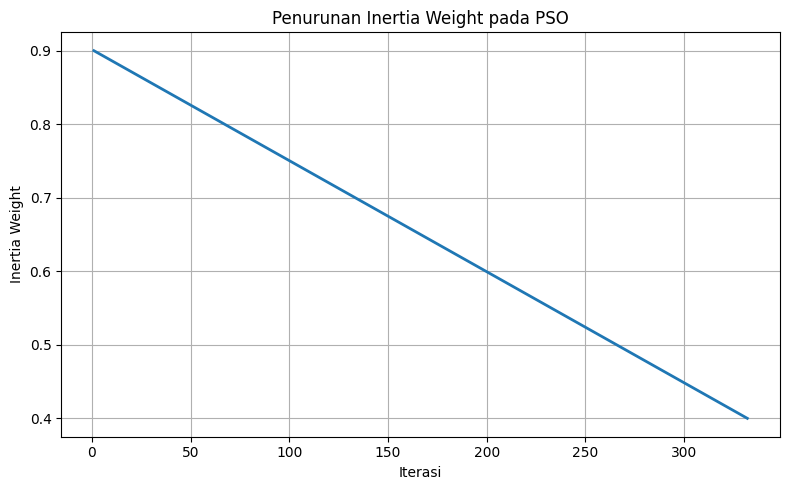

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parameter PSO sesuai program
PSO_W_MAX = 0.90
PSO_W_MIN = 0.40
PSO_ITER = 332

# Iterasi PSO
t = np.arange(PSO_ITER)
iterations = t + 1

# Rumus linear decreasing inertia weight
inertia_weights = (
    PSO_W_MAX
    - (PSO_W_MAX - PSO_W_MIN) * t / (PSO_ITER - 1)
)

# Tabel nilai inertia weight
inertia_df = pd.DataFrame({
    "Iterasi": iterations,
    "Inertia Weight": inertia_weights
})

display(inertia_df.head())
display(inertia_df.tail())

# Visualisasi
plt.figure(figsize=(8, 5))
plt.plot(iterations, inertia_weights, linewidth=2)
plt.xlabel("Iterasi")
plt.ylabel("Inertia Weight")
plt.title("Penurunan Inertia Weight pada PSO")
plt.grid(True)
plt.tight_layout()
plt.show()

# Summary

In [47]:
print("=== RINGKASAN STATISTIK DATASET AWAL ===")

summary_raw = pd.DataFrame({
    "count": df_raw.count(),
    "mean": df_raw.mean(),
    "median": df_raw.median(),
    "std": df_raw.std(),
    "min": df_raw.min(),
    "max": df_raw.max(),
    "missing_value": df_raw.isnull().sum()
})

display(summary_raw)

=== RINGKASAN STATISTIK DATASET AWAL ===


,count,mean,median,std,min,max,missing_value
AADI.JK,252,7049.199662,6862.818604,737.904450,5396.404297,9643.139648,1195
ADMR.JK,958,1291.979213,1262.880859,359.086548,128.670883,2849.821777,489
ADRO.JK,1447,1065.360278,1139.368042,542.519844,194.011871,2254.575195,0
AKRA.JK,1447,907.759551,1044.838623,374.569499,207.788986,1604.753784,0
AMMN.JK,594,7824.452862,7725.000000,2134.887195,1750.000000,13200.000000,853
AMRT.JK,1447,1907.247958,2034.000732,850.683835,579.390076,3523.521973,0
ANTM.JK,1447,1675.378085,1645.986084,683.370928,285.779785,3670.000000,0
ARTO.JK,1447,5263.732398,2700.000000,4976.021263,274.517670,19000.000000,0
ASII.JK,1447,4427.864360,4413.399414,751.947908,2213.114990,6725.000000,0
BBCA.JK,1447,7448.155890,7744.376953,1535.658547,3829.202148,10500.997070,0


In [48]:
print("=== RINGKASAN STATISTIK DATASET SETELAH CLEANING ===")

summary_clean = pd.DataFrame({
    "count": df_clean.count(),
    "mean": df_clean.mean(),
    "median": df_clean.median(),
    "std": df_clean.std(),
    "min": df_clean.min(),
    "max": df_clean.max(),
    "missing_value": df_clean.isnull().sum()
})

display(summary_clean)

=== RINGKASAN STATISTIK DATASET SETELAH CLEANING ===


,count,mean,median,std,min,max,missing_value
AADI.JK,252,7049.199662,6862.818604,737.904450,5396.404297,9643.139648,0
ADMR.JK,252,1061.528585,1015.000000,198.765097,671.947937,1600.000000,0
ADRO.JK,252,1739.723147,1706.279053,169.209760,1402.556396,2230.069092,0
AKRA.JK,252,1165.159630,1192.851685,90.850728,832.222107,1345.000000,0
AMMN.JK,252,7414.543651,7237.500000,955.755417,4610.000000,9550.000000,0
AMRT.JK,252,2281.872466,2250.000000,329.524424,1785.000000,3030.031494,0
ANTM.JK,252,2509.579498,2910.000000,772.385622,1314.547974,3670.000000,0
ARTO.JK,252,2017.559524,2005.000000,284.395452,1280.000000,2700.000000,0
ASII.JK,252,5090.100654,4654.994629,811.972930,4125.183105,6725.000000,0
BBCA.JK,252,8531.606042,8469.014648,584.717229,7202.388184,10047.386719,0


In [49]:
import pandas as pd

df_ga = pd.DataFrame(ga_results)
df_ga["algorithm"] = "GA"

df_pso = pd.DataFrame(pso_results)
df_pso["algorithm"] = "PSO"

df_sa = pd.DataFrame(sa_results)
df_sa["algorithm"] = "SA"

df_all_runs = pd.concat(
    [df_ga, df_pso, df_sa],
    ignore_index=True
)

print("Jumlah hasil setiap algoritma:")
print(df_all_runs["algorithm"].value_counts())

print("\nKolom data:")
print(df_all_runs.columns.tolist())

df_all_runs.to_csv(
    "COMNETSAT_100_Runs_All_Algorithms.csv",
    index=False
)

display(df_all_runs.head())

Jumlah hasil setiap algoritma:
algorithm
GA     100
PSO    100
SA     100
Name: count, dtype: int64

Kolom data:
['run', 'variance', 'annual_return', 'annual_volatility', 'sharpe_ratio', 'execution_time', 'weights', 'algorithm']


,run,variance,annual_return,annual_volatility,sharpe_ratio,execution_time,weights,algorithm
0,1,0.000136,0.255224,0.185339,1.120780,0.543576,"[0.013199264137370624, 0.00783790258841506, 0....",GA
1,2,0.000138,0.151553,0.186378,0.558293,0.498835,"[0.02415936510040883, 0.0008975687644600207, 0...",GA
2,3,0.000120,0.238406,0.173834,1.098208,0.491476,"[0.003202865296964461, 0.026003316114502052, 0...",GA
3,4,0.000128,0.207428,0.179508,0.890928,0.481653,"[0.016610165683870363, 0.017972122706462132, 0...",GA
4,5,0.000138,0.243043,0.186637,1.047719,0.485999,"[0.012907892855310823, 0.011303028850100354, 0...",GA


In [50]:
from google.colab import files

files.download("COMNETSAT_100_Runs_All_Algorithms.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>